# **Only for Run On Google Colab**

In [1]:
from google.colab import drive
import os
drive.mount('/content/drive')
if not os.path.exists('data'):
    !cp -r "/content/drive/MyDrive/DataMining_Project/data" .

Mounted at /content/drive


# **For Local Run**

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 51.6 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 58.3 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 61.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 61.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 56.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 48.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 67.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 50.4 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18/18 [seaborn]7/18 [seaborn]ib]n]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


الخطوة 1: استيراد المكتبات وتحديد المسارات النسبية (Setup & Relative Paths)
تضمن هذه الخطوة عمل الكود على أي جهاز بمجرد وجود مجلد data في نفس مسار السكريبت، دون الحاجة لتعديل أي مسارات يدوياً.

In [2]:
import os
import re
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# تحديد المسارات النسبية بناءً على موقع السكريبت الحالي
BASE_DIR = os.getcwd()
DATA_DIR = os.path.join(BASE_DIR, "data")
GRADES_PATH = os.path.join(DATA_DIR, "grades.xlsx")
ATTENDANCE_DIR = os.path.join(DATA_DIR, "attendance")
OUTPUT_PATH = os.path.join(BASE_DIR, "Student_Profiling_Results.xlsx")

# التحقق من وجود الملفات قبل البدء
assert os.path.exists(GRADES_PATH), f"ملف العلامات غير موجود في: {GRADES_PATH}"
assert os.path.exists(ATTENDANCE_DIR), f"مجلد الحضور غير موجود في: {ATTENDANCE_DIR}"
print("الخطوة 1 اكتملت: المسارات جاهزة وتم التحقق من وجود البيانات.")

الخطوة 1 اكتملت: المسارات جاهزة وتم التحقق من وجود البيانات.


الخطوة 2: استخراج وتجميع سجلات حضور Teams (Data Extraction & Section-Level Aggregation)
تتعامل هذه الخطوة مع البنية الخام لملفات حضور Teams (تخطي ترويسة الملخص المكونة من 9 صفوف، استبعاد المعلمين/المنظمين، تحويل المدة الزمنية العربية إلى دقائق، وتجميع حضور كل طالب عبر جميع الحصص والشعب).

In [3]:
def parse_arabic_duration(duration_str):
    """تحويل صيغة الوقت العربية (مثل: ٢ س ٤٠ د ٢ ث) إلى إجمالي الدقائق"""
    if pd.isna(duration_str):
        return 0.0
    text = str(duration_str).translate(str.maketrans('٠١٢٣٤٥٦٧٨٩', '0123456789'))

    h = int(re.search(r'(\d+)\s*س', text).group(1)) if re.search(r'(\d+)\s*س', text) else 0
    m = int(re.search(r'(\d+)\s*د', text).group(1)) if re.search(r'(\d+)\s*د', text) else 0
    s = int(re.search(r'(\d+)\s*ث', text).group(1)) if re.search(r'(\d+)\s*ث', text) else 0

    return round(h * 60 + m + (s / 60.0), 2)

def aggregate_teams_attendance(folder_path):
    """قراءة وتجميع كافة ملفات الحضور اليومية بمرونة عالية"""
    all_files = glob.glob(os.path.join(folder_path, "*.xlsx"))
    if not all_files:
        raise FileNotFoundError("لم يتم العثور على أي ملفات Excel داخل مجلد attendance.")

    daily_records = []
    for file_path in all_files:
        # 1. البحث التلقائي عن الصف الذي يحتوي على عناوين جدول المشاركين
        raw_df = pd.read_excel(file_path, header=None)
        header_idx = None
        for idx, row in raw_df.iterrows():
            row_str = " ".join(row.dropna().astype(str))
            if 'البريد الإلكتروني' in row_str or 'الاسم' in row_str:
                header_idx = idx
                break

        if header_idx is None:
            print(f"تنبيه: تم تخطي الملف {os.path.basename(file_path)} لعدم العثور على جدول المشاركين.")
            continue

        df = pd.read_excel(file_path, header=header_idx)
        df.columns = df.columns.str.strip()

        # 2. الإبقاء على الطلاب ("الحضور") واستبعاد المعلمين ("المنظم")
        if 'الدور' in df.columns:
            df = df[df['الدور'].astype(str).str.strip() == 'الحضور'].copy()

        # 3. البحث التلقائي عن عمود البريد الإلكتروني وعمود مدة الاجتماع (سواء بالهاء أو التاء المربوطة)
        email_col = next((c for c in df.columns if 'البريد' in c or 'UPN' in c), None)
        dur_col = next((c for c in df.columns if 'الاجتماع' in c or 'المدة' in c or 'المده' in c), None)

        if not email_col or not dur_col:
            print(f"تنبيه: أعمدة ناقصة في الملف {os.path.basename(file_path)}: {list(df.columns)}")
            continue

        df['Student_ID'] = df[email_col].astype(str).str.split('@').str[0].str.strip()
        df['Duration_Minutes'] = df[dur_col].apply(parse_arabic_duration)

        # تجميع دقائق الطالب في الحصة الواحدة
        session_summary = df.groupby('Student_ID', as_index=False)['Duration_Minutes'].sum()
        session_summary['Attended_Session'] = 1
        daily_records.append(session_summary)

    full_attendance = pd.concat(daily_records, ignore_index=True)

    student_attendance = full_attendance.groupby('Student_ID', as_index=False).agg(
        Total_Sessions=('Attended_Session', 'sum'),
        Total_Minutes=('Duration_Minutes', 'sum'),
        Avg_Minutes_Per_Session=('Duration_Minutes', 'mean')
    )
    return student_attendance

attendance_df = aggregate_teams_attendance(ATTENDANCE_DIR)
print(f"الخطوة 2 اكتملت بنجاح: تم تجميع سجلات الحضور لـ {len(attendance_df)} طالب.")

تنبيه: تم تخطي الملف session_ (113).xlsx لعدم العثور على جدول المشاركين.
تنبيه: تم تخطي الملف session_ (95).xlsx لعدم العثور على جدول المشاركين.
تنبيه: تم تخطي الملف session_ (87).xlsx لعدم العثور على جدول المشاركين.
تنبيه: تم تخطي الملف session_ (122).xlsx لعدم العثور على جدول المشاركين.
تنبيه: تم تخطي الملف session_ (94).xlsx لعدم العثور على جدول المشاركين.
تنبيه: تم تخطي الملف session_ (135).xlsx لعدم العثور على جدول المشاركين.
تنبيه: تم تخطي الملف session_ (155).xlsx لعدم العثور على جدول المشاركين.
تنبيه: تم تخطي الملف session_ (115).xlsx لعدم العثور على جدول المشاركين.
تنبيه: تم تخطي الملف session_ (157).xlsx لعدم العثور على جدول المشاركين.
تنبيه: تم تخطي الملف session_ (161).xlsx لعدم العثور على جدول المشاركين.
تنبيه: تم تخطي الملف session_ (103).xlsx لعدم العثور على جدول المشاركين.
تنبيه: تم تخطي الملف session_ (159).xlsx لعدم العثور على جدول المشاركين.
تنبيه: تم تخطي الملف session_ (152).xlsx لعدم العثور على جدول المشاركين.
تنبيه: تم تخطي الملف session_ (131).xlsx لعدم العثور ع

الخطوة 3: تنظيف البيانات ودمج كشوف العلامات وتعويض القيم المفقودة (Data Cleaning, Merging & Missing Value Imputation)
تنفذ هذه الخطوة ما ورد في الـ Proposal بخصوص دمج كشوف العلامات عبر الشعب المتعددة مع سجلات الحضور، ومعالجة القيم المفقودة (Missing Value Imputation) للطلاب الذين لم يسجلوا حضوراً أو لديهم علامات ناقصة.

In [4]:
# 1. قراءة كشف العلامات الموحد
grades_df = pd.read_excel(GRADES_PATH)
grades_df.columns = grades_df.columns.str.strip()

# إزالة عمود هوية الطالب المكرر إن وجد
grades_df = grades_df.loc[:, ~grades_df.columns.duplicated()]
if 'هوية الطالب.1' in grades_df.columns:
    grades_df = grades_df.drop(columns=['هوية الطالب.1'])

# البحث التلقائي عن عمود الهوية والشعبة
id_col = next(c for c in grades_df.columns if 'هوية' in c)
section_col = next(c for c in grades_df.columns if 'شعبة' in c or 'الشعبة' in c)

grades_df['Student_ID'] = grades_df[id_col].astype(str).str.strip()

# 2. البحث التلقائي عن أعمدة المواد الأربع ومعالجة القيم المفقودة بمتوسط الشعبة
eng_col = next(c for c in grades_df.columns if 'إنجليز' in c or 'انجليز' in c)
sci_col = next(c for c in grades_df.columns if 'علوم' in c)
math_col = next(c for c in grades_df.columns if 'رياضيات' in c)
arb_col = next(c for c in grades_df.columns if 'عربي' in c)

subjects = [eng_col, sci_col, math_col, arb_col]
print("تم التعرف على أعمدة المواد التالية:", subjects)

for sub in subjects:
    grades_df[sub] = pd.to_numeric(grades_df[sub], errors='coerce')
    grades_df[sub] = grades_df[sub].fillna(grades_df.groupby(section_col)[sub].transform('mean'))

# حساب المعدل العام للطالب (GPA)
grades_df['GPA'] = grades_df[subjects].mean(axis=1).round(2)

# 3. دمج كشف العلامات مع بيانات الحضور المجمعة (Left Join)
master_df = pd.merge(grades_df, attendance_df, on='Student_ID', how='left')

# 4. تعويض القيم المفقودة في الحضور بـ 0 (Missing Value Imputation للطلاب الغائبين كلياً)
attendance_cols = ['Total_Sessions', 'Total_Minutes', 'Avg_Minutes_Per_Session']
master_df[attendance_cols] = master_df[attendance_cols].fillna(0)

print(f"الخطوة 3 اكتملت بنجاح: الجدول الموحد جاهز ويحتوي على {len(master_df)} طالب.")
display(master_df[['Student_ID', 'اسم الطالب', section_col, 'Total_Sessions', 'Avg_Minutes_Per_Session', 'GPA']].head())

تم التعرف على أعمدة المواد التالية: ['اللغــه\xa0الإنجليزية', 'العلوم', 'الرياضيات', 'اللغة العربية']
الخطوة 3 اكتملت بنجاح: الجدول الموحد جاهز ويحتوي على 598 طالب.


,Student_ID,اسم الطالب,الشعبة,Total_Sessions,Avg_Minutes_Per_Session,GPA
0,434642641,إبراهيم محمد إبراهيم مونس,1,90.0,49.724889,98.50
1,434792040,احمد محمد شعبان حمد,1,37.0,51.347838,96.50
2,434602603,إلينا احمد سعيد النخاله,1,2.0,13.645000,96.00
3,434745394,أمير إبراهيم مصطفى حماد,1,81.0,42.393210,95.75
4,434453320,إيمان محمود جمال عيد,1,4.0,26.542500,96.00


الخطوة 4: توحيد المقاييس وتحديد العدد الأمثل للمجموعات (Feature Standardization & Optimal K)تُطبق هذه الخطوة توحيد المقاييس (StandardScaler) كما هو محدد في منهجية المشروع؛ لأن عدد الدقائق وعدد الحصص يختلفان في المقياس عن المعدل الأكاديمي (من 100)، ثم تستخدم طريقة المرفق (Elbow Method) لتحديد عدد المجموعات الأمثل ($K$).

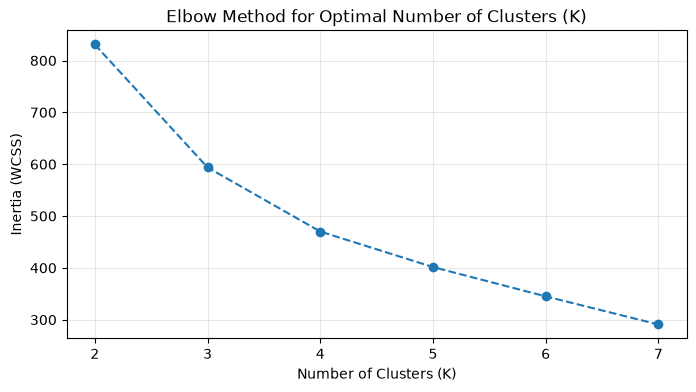

الخطوة 4 اكتملت: تم توحيد المقاييس ورسم منحنى المرفق لاختيار K.


In [5]:
# اختيار الميزات الأساسية لقياس الانضباط والتحصيل الأكاديمي
features = ['Total_Sessions', 'Avg_Minutes_Per_Session', 'GPA']
X = master_df[features]

# توحيد المقاييس (Standardization: Mean = 0, Std = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# حساب Inertia لتحديد العدد الأمثل للمجموعات (Elbow Method)
inertia = []
K_range = range(2, 8)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

# رسم منحنى Elbow
plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker='o', linestyle='--', color='#1f77b4')
plt.title('Elbow Method for Optimal Number of Clusters (K)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.grid(True, alpha=0.3)
plt.show()

print("الخطوة 4 اكتملت: تم توحيد المقاييس ورسم منحنى المرفق لاختيار K.")

الخطوة 5: تطبيق خوارزمية K-Means وتحليل المجموعات (K-Means Clustering & Profiling)
تقوم هذه الخطوة بتشغيل خوارزمية K-Means Clustering، وحساب معامل التماسك (Silhouette Score)، واستخراج خصائص كل مجموعة لتفسير العلاقة بين الانضباط في الحضور والتحصيل الأكاديمي.

In [6]:
# اختيار K=4 (يمكن تعديله بناءً على رسم Elbow في الخطوة السابقة)
OPTIMAL_K = 4
kmeans = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
master_df['Cluster'] = kmeans.fit_predict(X_scaled)

# تقييم جودة التجميع باستخدام Silhouette Score
sil_score = silhouette_score(X_scaled, master_df['Cluster'])
print(f"مؤشر جودة التجميع (Silhouette Score): {sil_score:.3f}")

# إعادة التقاط أسماء أعمدة المواد الأربع تلقائياً من الجدول الموحد
subjects = [
    next(c for c in master_df.columns if 'إنجليز' in c or 'انجليز' in c),
    next(c for c in master_df.columns if 'علوم' in c),
    next(c for c in master_df.columns if 'رياضيات' in c),
    next(c for c in master_df.columns if 'عربي' in c)
]

# إنشاء جدول ملخص لخصائص كل مجموعة (Cluster Profiling)
cluster_profile = master_df.groupby('Cluster')[features + subjects].mean().round(2)
cluster_profile['Student_Count'] = master_df['Cluster'].value_counts()
cluster_profile['Percentage (%)'] = ((cluster_profile['Student_Count'] / len(master_df)) * 100).round(1)

print("\n=== جدول تحليل أنماط الطلاب (Cluster Profiling) ===")
display(cluster_profile)

مؤشر جودة التجميع (Silhouette Score): 0.411

=== جدول تحليل أنماط الطلاب (Cluster Profiling) ===


,Total_Sessions,Avg_Minutes_Per_Session,GPA,اللغــه الإنجليزية,العلوم,الرياضيات,اللغة العربية,Student_Count,Percentage (%)
Cluster,,,,,,,,,
0,3.01,6.97,95.68,95.31,95.56,95.33,96.54,142,23.7
1,137.98,51.17,98.71,98.74,98.36,98.87,98.86,181,30.3
2,37.94,40.89,95.74,95.37,95.59,95.65,96.34,186,31.1
3,19.75,20.65,98.16,98.57,97.73,98.03,98.31,89,14.9


الخطوة 6: التمثيل البصري وحفظ النتائج النهائية (Visualization & Export)
ترسم هذه الخطوة العلاقة بين الحضور والمعدل الأكاديمي موزعة حسب المجموعات، وتحفظ الجدول النهائي في ملف Excel بجانب السكريبت لدعم التدخلات التربوية الموجهة (Targeted Instructional Interventions).

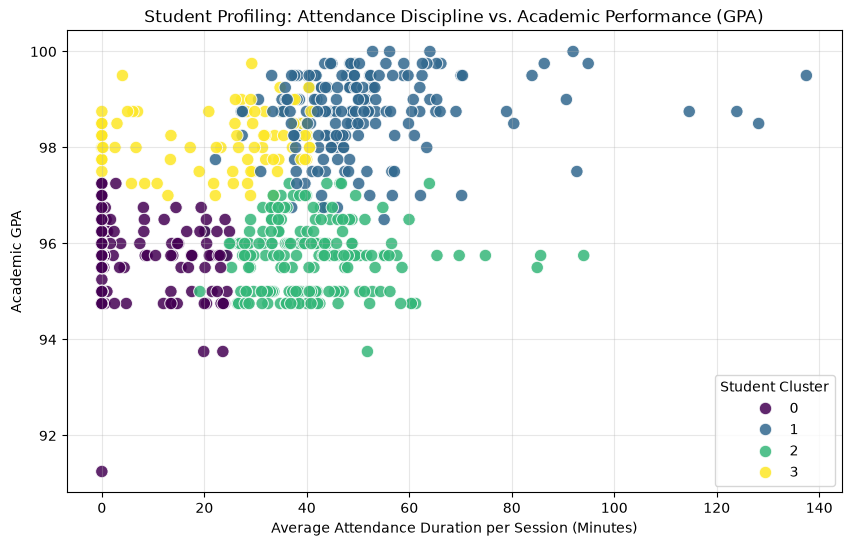

الخطوة 6 اكتملت: تم حفظ التقرير النهائي والنتائج في الملف: /workspaces/DeiaaAbdullwahhab-Data_Mining_Project_Deiaa_Abdullwahhab/Student_Profiling_Results.xlsx


In [7]:
# رسم العلاقة بين متوسط دقائق الحضور والمعدل الأكاديمي لكل مجموعة
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=master_df,
    x='Avg_Minutes_Per_Session',
    y='GPA',
    hue='Cluster',
    palette='viridis',
    s=80,
    alpha=0.85
)
plt.title('Student Profiling: Attendance Discipline vs. Academic Performance (GPA)')
plt.xlabel('Average Attendance Duration per Session (Minutes)')
plt.ylabel('Academic GPA')
plt.legend(title='Student Cluster')
plt.grid(True, alpha=0.3)
plt.show()

# حفظ النتائج النهائية في ملف Excel في نفس مجلد المشروع
with pd.ExcelWriter(OUTPUT_PATH, engine='openpyxl') as writer:
    master_df.to_excel(writer, sheet_name='Students_Clusters', index=False)
    cluster_profile.to_excel(writer, sheet_name='Cluster_Summary')

print(f"الخطوة 6 اكتملت: تم حفظ التقرير النهائي والنتائج في الملف: {OUTPUT_PATH}")